**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

This notebook takes the alpha diversity trajectories and models they using a perturbation-recovery model. Our perturbation-recovery model is essentially a non-linear fit that assumes the data looks like a 1/x curve (two aspmyotoes at 0 and the intercept); see traces below.

Our model is defined as

$y(t) = mt^{-1} + b$

where $y(t)$ is the percentage of baseline diversity $t$ days after treatment, $m$ is rate at which diveristy recovers, and $b$ is the new steady state to which diveristy recovers.

For this model to work, we assume that 

1. Without intervention, the diversity would remain at approximately steady state over the study period.<br>While we see changes in the microbiome with age, this is generally over decades.
3. Treatment is short compared to the length of follow up, and therefore we can assume that threatment is an instanteous or close to instantenous effect.<br>This is a somewhat tenous assumption, but not a terrible one as 5 days is short in a 365 day timeline.
4. The treatment does not have lasting effects on the rate of bacterial growth, meaning that an delayed recovery is assumed to be due to a greater perturbation (more ground to recover) rather than a slowing of growth.<br>This is also a hard assumption to test. Most of hte anitbiotic teratments here are excreted within 24 hours of treatment, so the mechanism should not be due to sustained antibiotic exposure. However, its possible that antibiotics might induce genomic changes leading to spore formation and that delay recovery.

In [1]:
import itertools as it
import re
import os
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import numpy as np
import pandas as pd
import scipy
from scipy.stats import studentized_range as q_dist
import seaborn as sn
import skbio
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.image as mpimg

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.longitudinal.actions as q2_longitudinal

from scripts.arg_lme import fit_full_lme

from IPython.display import HTML

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
hide_axes = dict(left=False, labelleft=False,
                 right=False, labelright=False,
                 length=0,
                 labelsize=0)

In [3]:
%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)


In [4]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}

In [5]:
clean_metrics = {'observed_features': 'Observed Species',
                 'unweighted_unifrac': 'unweighted\nUniFrac',
                 'weighted_unifrac': 'weighted\nUniFrac',
                 'braycurtis': 'Bray Curtis',
                 'rpca': 'rPCA\nAitchison',
                 'phylo_rpca': 'phylo rPCA\nAitchison'
                 }


# Data

## Metadata

In [6]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()

## Alpha Diversity

In [7]:
alpha_dir = 'final-data/03.alpha-diveristy'
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
    for metric in alpha_metrics
    }
meta_a = pd.DataFrame({metric: art.view(pd.Series) 
                       for metric, art in alpha_q2.items()})
meta_a[['host_subject_id', 'timepoint']] = meta[['host_subject_id', 'timepoint']]
meta_a.sort_values(['host_subject_id', 'timepoint'], ascending=True, inplace=True)
meta_a0 = meta_a.groupby('host_subject_id').first()[alpha_metrics]
alpha0 = meta_a0.loc[meta_a['host_subject_id'], alpha_metrics]
alpha0.index = meta_a.index

In [8]:
a_traces_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg_from_baseline.qza')
    for metric in np.hstack([alpha_metrics, 'depth'])
    }
a_traces = pd.DataFrame(
    {metric: art.view(pd.Series) for metric, art in a_traces_q2.items()
     if metric in alpha_metrics}
)

## Combined data

In [9]:
meta_t = pd.concat(
    axis=1, 
    objs=[meta,
          a_traces_q2['depth'].view(pd.Series).to_frame().rename(columns={'Difference': 'depth_d'}) / 1e5,
          (a_traces / alpha0 * 100), 
          alpha0.add_suffix('_0'),
          (alpha0 > meta_a0.mean()).add_suffix('_0_cat') * 1,
         ]
    )
meta_t.replace({metric: {np.nan: 0} for metric in alpha_metrics},
              inplace=True)
meta_t.sort_values(['abx_code2', 'host_subject_id', 'timepoint'],
                   ascending=True, inplace=True)
meta_t['first_extraction'] = \
    meta_t['host_subject_id'].replace(meta_t.groupby('host_subject_id')['extraction_no'].first())
meta_t['extr_not0'] = (meta_t['extraction_no'] != meta_t['first_extraction']) * 1
meta_t['days_inv'] = 30 / meta_t['days_since_intervention']
meta_t['abx_code2'] = meta_t['abx_code2'].astype(int)
meta_t['period'] = (meta_t['timepoint'].astype(float) > 0) * 1 + \
    (meta_t['timepoint'].astype(float) > 3) * 1

# Visualization

In [11]:
trace_w = meta_t.pivot(index=['abx_code2', 'host_subject_id'],
                       columns='timepoint',
                       values=alpha_metrics)
trace_summary = \
    meta_t.groupby(['abx_code2', 'timepoint'])[alpha_metrics].describe()
trace_summary.columns.set_names(['metric', 'statistic'], inplace=True)
trace_summary = trace_summary.unstack().unstack().reset_index()
trace_summary.rename(columns={0: 'value'}, inplace=True)
trace_summary['abx_code2'] = trace_summary['abx_code2'].astype(int)
trace_summary = trace_summary.pivot(
    index=['metric', 'abx_code2', 'timepoint'],
    columns='statistic',
    values='value',
    )
trace_summary['t'] = scipy.stats.t.ppf(0.975, df=trace_summary['count'] - 1)
trace_summary['sem'] = trace_summary['std'] / np.sqrt(trace_summary['count'] - 1)
trace_summary['ci'] = trace_summary['sem'] * trace_summary['t']

trace_summary = trace_summary.unstack()


In [12]:
def _plot_forest(ax, abx, sum_df, error_kws=None, shade_kws=None):
    """
    Makes a forest plot square
    """
    error_kwargs = dict(capsize=3,
                        marker='.',
                        linestyle='',
                        zorder=3,
                        )
    if isinstance(error_kws, dict):
        error_kwargs.update(error_kws)

    shade_kwargs = dict(alpha=0.25,
                        linewidth=0,
                        zorder=0,
                        )
    if isinstance(shade_kws, dict):
        shade_kwargs.update(shade_kws)
    
    if abx > 0:
        ax.fill_between(np.arange(7),
                        sum_df.loc[0, 'mean'] - sum_df.loc[0, 'ci'],
                        sum_df.loc[0, 'mean'] + sum_df.loc[0, 'ci'],
                        color=colors[0],
                        **shade_kwargs,
                        )
    ax.errorbar(x=np.arange(0, 7),
                y=sum_df.loc[abx, 'mean'],  
                yerr=sum_df.loc[abx, 'ci'],
                color=colors[int(abx)],
                **error_kwargs,
                )


In [13]:
def _plot_trace(ax, abx, sum_df, trace_df, shade_kws=None, mean_kws=None, trace_kws=None, scale=0.05):
    """
    Plots a per individual trace
    """
    # Shade kws
    shade_kwargs = dict(color=colors[abx],
                        alpha=0.25,
                        linewidth=0,
                        zorder=0,)
    if isinstance(shade_kws, dict):
        shade_kwargs.update(shade_kws)
    # Mean trace kwargs
    mean_kwargs = dict(linestyle='-',
                       marker='.',
                       color=colors[abx],
                       zorder=2,)
    if isinstance(mean_kws, dict):
        mean_kwargs.update(mean_kws)
    # Trace_kwargs 
    trace_kwargs = dict(linestyle='-',
                        marker='.',
                        linewidth=1/3,
                        markersize=1,
                        color='#525252')
    if isinstance(trace_kws, dict):
         trace_kwargs.update(trace_kws)

    # Gloabl alpha diveristy
    ymean = sum_df.loc[abx, 'mean']
    yerr = sum_df.loc[abx, 'ci']
    ax.fill_between(x=np.arange(7), y1=ymean - yerr, y2=ymean + yerr,
                    **shade_kwargs) 
    ax.plot(np.arange(7), ymean, **mean_kwargs)
    

    trace_x = np.vstack([trace_df.columns.astype(float)] * len(trace_df)) + \
        np.vstack([np.random.normal(size=len(trace_df))] * 7).T * scale
    
    ax.plot(trace_x.T, trace_df.T, **trace_kwargs)

In [14]:
def _format_alpha_axes(ax, abx, bottom):
    """
    Lazy function to clean up axes
    """
    ax.set_xticks(np.arange(7))
    ax.set_xlim(-0.5, 6.5)
    ax.set_xticklabels([-1, 7, 14, 30, 90, 180, 365], size=9, 
                       rotation=90, ha='center', va='top')
    ax.xaxis.set_tick_params(bottom=False, right=False, length=0,
                             labelbottom=bottom)
    ax.yaxis.set_tick_params(left=True, labelleft=(abx==0),
                             right=False, labelsize=9)
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:1.0f}%'))

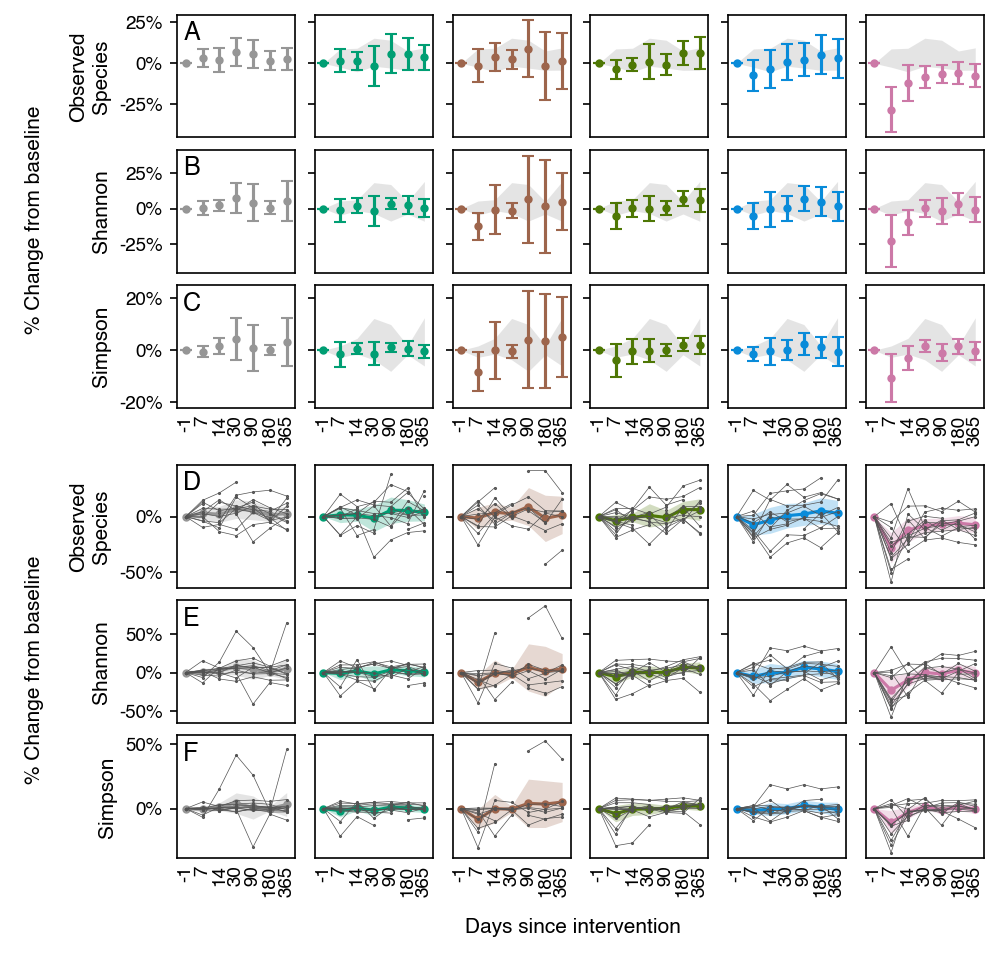

In [15]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 6.25), facecolor='None')
[[figya, figa], [figyb, figb],[_, figx]] = \
    figa.subfigures(3, 2, 
                    width_ratios=[0.25, 6], 
                    height_ratios=[3, 3, 0.25],
                    facecolor='None'
                    )
gsa = figa.add_gridspec(3, 6)
gsb = figb.add_gridspec(3, 6)
for row, metric in enumerate(alpha_metrics):
    metric_clean = clean_metrics.get(metric, metric.title()).replace(' ', '\n')
    msummary_df = trace_summary.xs(metric, level='metric')
    for abx, trace_df in trace_w[metric].groupby('abx_code2'):
        if abx == 0:
            axa = figa.add_subplot(gsa[row, abx])
            axb = figb.add_subplot(gsb[row, abx])
            axa.set_ylabel(metric_clean, size=10)
            axb.set_ylabel(metric_clean, size=10)
            axra = axa
            axrb = axb
        else:
            axa = figa.add_subplot(gsa[row, abx], sharex=axa, sharey=axa)
            axb = figb.add_subplot(gsb[row, abx], sharex=axb, sharey=axb)
        _plot_forest(axa, abx, msummary_df)
        _format_alpha_axes(axa, abx, row == 2)

        _plot_trace(axb, abx, msummary_df, trace_df, scale=0)
        _format_alpha_axes(axb, abx, row == 2) 
    axra.text(x=axra.get_xlim()[0] + 0.05 * np.diff(axra.get_xlim()), 
              y=axra.get_ylim()[1] - 0.05 * np.diff(axra.get_ylim()), 
              s='ABC'[row], 
              size=12, ha='left', va='top')
    axrb.text(x=axrb.get_xlim()[0] + 0.05 * np.diff(axrb.get_xlim()), 
              y=axrb.get_ylim()[1] - 0.05 * np.diff(axrb.get_ylim()), 
              s='DEF'[row], 
              size=12, ha='left', va='top')

axy = figya.add_subplot(1,1,1, position=(0.05, 0.1, 0.9, 0.85), facecolor='None')
axy.xaxis.set_tick_params(**hide_axes)
axy.yaxis.set_tick_params(**hide_axes)
axy.text(0.5, 0.5, '% Change from baseline', size=10, 
         rotation=90, ha='center', va='center')
sn.despine(figya, left=True, right=True, top=True, bottom=True)
axy = figyb.add_subplot(1,1,1, position=(0.05, 0.1, 0.9, 0.85), facecolor='None')
axy.xaxis.set_tick_params(**hide_axes)
axy.yaxis.set_tick_params(**hide_axes)
axy.text(0.5, 0.5, '% Change from baseline', size=10, 
         rotation=90, ha='center', va='center')
sn.despine(figyb, left=True, right=True, top=True, bottom=True)
axx = figx.add_subplot(1,1,1, position=(0.1, 0, 0.90, 1), facecolor='None')
axx.xaxis.set_tick_params(**hide_axes)
axx.yaxis.set_tick_params(**hide_axes)
axx.text(0.5, 0.5, 'Days since intervention', size=10, 
         ha='center', va='center')
sn.despine(figx, left=True, right=True, top=True, bottom=True)

**Figure S6. Change in alpha diversity over time among participants.**
(A-C) The estimated change in alpha diversity (mean ± 95% confidence interval) following treatment. Gray shading indicates 95% CI for the untreated group. (D-F) Traces showing within individual changes in alpha diversity over the follow up time. The main line shows the mean, the shaded area is the 95% confidence interval. Alpha diversity from each participant is shown as a connected trace. Traces are shown for metric with ascending Hill Numbers: (A,D) Observed Species, (B,E) Shannon Diversity, and (C,F) Simpson Diversity.

# Modeling

In [16]:
meta_r = meta_t.loc[~meta_t['timepoint'].isin(['0.0'])].copy()

## Adjustments

In [17]:
ref_eqs = {
    'crude': 'depth_d',
    'model 1': 'depth_d + C(extraction_no)',
    'model 2': ('depth_d + C(extraction_no) + after_travel_na_eu'),
    'model 3': ('depth_d + C(extraction_no) + after_travel_na_eu + age + sex + vegetarian'),
}

In [18]:
def find_abx(x, ref_value):
    """
    Looks for the antibiotic code
    """
    if 'abx_code2' in x:
        return x.split(':')[0].split(')[T.')[1].replace(']', '')
    else:
        return str(ref_value)

def _extract_recovery(fit, metric, model, slope=False, ref_value='0'):
    """
    Extracts the recovery fit for the data
    """
    # Extracts the parameters for the fit
    params = pd.concat(
        axis=1, 
        objs=[fit.params, fit.bse, fit.tvalues, fit.pvalues, fit.conf_int()]
    )
    params.columns = ['params', 'bse', 't_value', 'p_value', 'ci_lo', 'ci_hi']
    def _check_var(v):
        return (('extraction_no' in v) | 
                ('after_travel' in v) | 
                ('depth' in v) | 
                ('age' in v) | 
                ('sex' in v) | 
                ('veg' in v) |
                ('Group Var' in v) | 
                ('Var' in v) | 
                ('Cov' in v)
                )
        
    # Drops out the extraction number
    params.drop(index=[v for v in params.index if _check_var(v)],
                inplace=True)
    
    idx = params.index.to_frame()[0]
    params['abx_code'] = \
        params.index.to_frame()[0].apply(find_abx, ref_value=ref_value)
    params['slope'] = \
        params.index.to_frame()[0].apply(lambda x: 'days_inv' in x)
    params['metric'] = metric
    params['model'] = model
    params['rs_slope'] = slope 
    params['ref_value'] = ref_value
    
    return params
def _build_tidy(x):
    if str(x['ref_value']) == str(x['abx_code']):
        return '0 (ref)'
    else:
        return '{params:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x)


In [19]:

def _sum_params(params, inter_id, ref_id, ref_value='0'):
    """
    Gets the summed parameter value
    """
    new_id = 'C(abx_code2)[T.{0}]{1}'.format(
        ref_value, {'days_inv': ':days_inv'}.get(ref_id, ''))
    params2 = params.loc[inter_id].copy()
    params2.loc[new_id] = 0
    params2 = params2 + params.loc[ref_id]

    return params2.sort_index()

def _sum_vcov(vcov, inter_ids, ref_id, ref_value='0'):
    """
    Gets the summed variance, iterating through matrix
    """
    new_id = 'C(abx_code2)[T.{0}]{1}'.format(
        ref_value, {'days_inv': ':days_inv'}.get(ref_id, ''))
    
    var = {id_: vcov.loc[[ref_id, id_], [ref_id, id_]].sum().sum()
           for id_ in  inter_ids}
    var[new_id] = vcov.loc[ref_id, ref_id]
    
    return pd.Series(var).sort_index()
    
def _expand_interaction(fit_, metric, model, rs_slope=False, ref_value='0', alpha=0.05):
    """
    Collapses interaction to get the variance
    """
    params = fit_.params
    vcov = fit_.cov_params()
    nobs = fit_.nobs

    inter_b = [v for v in params.index if (('abx' in v)) & (':' not in v)]
    inter_m = [v for v in params.index if ':days_inv' in v]

    ref_b = 'Intercept'
    ref_m = 'days_inv'

    # Gets the summed parameters for the intercept
    param_b = _sum_params(params, inter_b, ref_b, ref_value=ref_value)
    param_m = _sum_params(params, inter_m, ref_m, ref_value=ref_value)
    exp_params = pd.concat([param_b, param_m])

    # Gets the summed variance
    var_b = _sum_vcov(vcov, inter_b, ref_b, ref_value=ref_value)
    var_m = _sum_vcov(vcov, inter_m, ref_m, ref_value=ref_value)

    # Gets the pooled sem
    sem_b = np.sqrt(var_b) * 2 / np.sqrt(nobs)
    sem_m = np.sqrt(var_m) * 2 / np.sqrt(nobs)
    exp_sem = pd.concat([sem_b, sem_m])

    min_t = scipy.stats.t.ppf(1-alpha / 2, nobs - 1)
    
    summary = pd.DataFrame({'param': exp_params, 
                            'sem': exp_sem,
                            'width': exp_sem * min_t,
                            'slope': exp_params.index.isin(param_m.index),
                            'abx': pd.Series({v: v.split('T.')[1].split(']')[0] 
                                              for v in exp_params.index}),
                            })
    summary['model'] = model
    summary['metric'] = metric
    summary['ref_value'] = ref_value
    summary['rs_slope'] = rs_slope

    
    return summary

# Alpha diveristy

We'll fit the models using a random intercept (the original fit) and random slope, and adjust for difference sets of confounders, and then we'll extract the parameters and data for plotting.

In [20]:
fit_untreat = {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric} ~ C(abx_code2)*days_inv + {ref_eq}',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ days_inv'])
    for metric in alpha_metrics
    }

In [21]:
fit_unt_exp_params = \
    pd.concat([_expand_interaction(fit_, *keys) 
               for keys, fit_ in fit_untreat.items()])

In [22]:
fit_unt_params = \
    pd.concat([_extract_recovery(fit_, *keys) 
               for keys, fit_ in fit_untreat.items()])
fit_unt_params.set_index(['metric', 'slope', 'model', 'rs_slope', 'ref_value', 'abx_code'],
                         inplace=True)

I want to look at two models here: the main model and a baseline adjsuted model with a random intercept.

In [23]:
sub_re = fit_unt_params.copy().xs(0, level='rs_slope')
sub_re.drop(index=['crude', 'model 1'], level='model', inplace=True)
sub_re.reset_index(level=['ref_value'], drop=True, inplace=True)
sub_re.reset_index(inplace=True)

sub_re['width'] = sub_re['ci_hi'] - sub_re['params']
sub_re['tidy'] = sub_re.apply(
    lambda x: '{params:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
sub_re['tidy'] = \
    sub_re['tidy'].mask(sub_re['abx_code'].isin(['0', 0]), '0 (ref)')
sub_re['params'] = sub_re['params'].mask(sub_re['abx_code'].isin(['0', 0]), 0)
sub_re['width'] = sub_re['width'].mask(sub_re['abx_code'].isin(['0', 0]), np.nan)
sub_re['p_value'] = sub_re['p_value'].mask(sub_re['abx_code'].isin(['0', 0]), 1)


sub_re['y'] = 5 - sub_re['abx_code'].astype(int) + \
    sub_re['model'].replace({'model 2': 1, 'model 3': -1}) * 0.2
sub_re['color'] = sub_re['abx_code'].replace(abx_colors)
sub_re['facecolor'] = sub_re['color'].mask(sub_re['p_value'] >= 0.05, 'w')
sub_re['marker'] = sub_re['model'].replace({'model 2': 's', 'model 3': 'o'})



In [24]:
def _get_abx(x):
    """Pulls antibiotic from string"""
    return x.split('T.')[1].split(']')[0]
    
def _get_q_params(b1, b2, slope, params, vcov, n_samp):
    """
    Calculates the difference, sem, and dof for samples
    """
    abx1 = _get_abx(b1)
    abx2 = _get_abx(b2)
    # Difference in means (directed)
    xd = params[b2] - params[b1]

    # Variance
    var = (vcov.loc[[b1, b2], [b1, b2]].values * np.array([[1, -1], [-1, 1]])).sum()

    return {'diff': xd, 'var': var, 
            'n0': n_samp[abx1], 'n1': n_samp[abx2], 
            'abx0': abx2, 'abx1': abx1,
            'slope': slope}

In [25]:
def _tukey_posthoc_inter(fit_, metric, model, rs_slope=0, ref_value='0', alpha=0.05):
    """
    Calculates a tukey posthoc test with an interaction model and limited 
    posthoc testing
    """
    params = fit_.params
    vcov = fit_.cov_params()
    var = pd.Series(np.diag(vcov), vcov.index)
    nobs = fit_.nobs
    k_fe = fit_.k_fe
    n_samp = meta['abx_code2'].value_counts()

    # Gets the list of baseline and slope parameters
    inter_b = [v for v in params.index if (('abx' in v)) & (':' not in v)]
    inter_m = [v for v in params.index if ':days_inv' in v]
    
    # Extracts the difference, pooled variance, and sample sizes
    all_comp = {(b1, b2): _get_q_params(b1, b2, False, params, vcov, n_samp)
                for (b1, b2) in it.combinations(inter_b, 2)}
    all_comp.update({(b1, b2): _get_q_params(b1, b2, True, params, vcov, n_samp)
                     for (b1, b2) in it.combinations(inter_m, 2)})
    all_comp = pd.DataFrame.from_dict(all_comp, orient='index')

    # Exapnds for qstat and width. We use 2 to reflec thte pairwise test...
    # I cant figure out how to get the 6 k values to work in a way that
    # makes sense... 
    all_comp['sem'] = \
        np.sqrt(all_comp['var'] / (all_comp[['n0', 'n1']].mean(axis=1)))
    all_comp['q_stat'] = np.absolute(all_comp['diff']) / all_comp['sem']
    all_comp['dof'] = (all_comp[['n0', 'n1']] - 1).sum(axis=1)
    all_comp['p_value'] = \
        q_dist.pdf(all_comp['q_stat'], df=all_comp['dof'], k=2)
    all_comp['width'] = \
        all_comp['sem'] * q_dist.ppf(1 - alpha / 2, df=all_comp['dof'], k=2)

    # Selects key values
    all_comp = all_comp[['diff', 'sem', 'width', 'q_stat', 'p_value',
                         'abx0', 'abx1', 'slope']].copy()
    all_comp['metric'] = metric
    all_comp['model'] = model
    all_comp['rs_slope'] = rs_slope
    all_comp['ref_value'] = ref_value

    return all_comp

In [26]:
posthoc_unt = pd.concat(
    axis=0, 
    objs=[_tukey_posthoc_inter(fit_, *keys) 
          for keys, fit_ in fit_untreat.items()]
    )

In [27]:
posthoc_unt.set_index(['slope', 'metric', 'model', 'rs_slope', 'abx0', 'abx1'],
                      inplace=True)

In [28]:
ph_main = posthoc_unt.xs('model 2', level='model')
ph_main = ph_main.xs(0, level='rs_slope').copy()
ph_main['ci_lo'] = ph_main['diff'] - ph_main['width']
ph_main['ci_hi'] = ph_main['diff'] + ph_main['width']

In [29]:
def _tidy_p(x):
    if x >= 0.01:
        return f'{x:1.2f}'
    elif x >= 0.001:
        return f'{x:1.3f}'
    elif x < 1e-16:
        return '>1e-16'
    else:
        return f'{x:1.0e}'
ph_main['tidy'] = ph_main.apply(
    lambda x: '{diff:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
ph_main['p_tidy'] = ph_main['p_value'].apply(_tidy_p)

In [38]:
ph_wide = \
    ph_main.reset_index().melt(id_vars=['slope', 'metric', 'abx0', 'abx1'],
                               value_vars=['tidy', 'p_tidy'],
                               var_name='stat',
                               value_name='value')
ph_wide = \
    ph_wide.pivot(index=['metric', 'abx0', 'abx1'],
                  columns=['slope', 'stat'],
                  values='value')
ph_wide.sort_index(axis='columns', inplace=True, ascending=[False, False])
ph_wide.sort_index(axis='index', inplace=True, ascending=True)
ph_wide.rename(abx_names, inplace=True)

**Table S3**

In [39]:
ph_wide

slope                                                           True           \
stat                                                             tidy  p_tidy   
metric            abx0           abx1                                           
observed_features pivmecillinam  nitrofurantoin   -0.21 (-0.74, 0.31)    0.37   
                  co-trimoxazole nitrofurantoin  -0.94 (-1.35, -0.52)   3e-06   
                                 pivmecillinam   -0.72 (-1.20, -0.25)   0.002   
                  ceftibuten     nitrofurantoin  -2.36 (-2.81, -1.92)  >1e-16   
                                 pivmecillinam   -2.15 (-2.66, -1.63)   5e-16   
                                 co-trimoxazole  -1.42 (-1.81, -1.03)   2e-13   
                  ciprofloxacin  nitrofurantoin  -2.99 (-3.41, -2.57)  >1e-16   
                                 pivmecillinam   -2.77 (-3.26, -2.29)  >1e-16   
                                 co-trimoxazole  -2.05 (-2.42, -1.68)  >1e-16   
                                 ceftibuten      -0.63 (-1.03, -0.23)   0.001   
shannon           pivmecillinam  nitrofurantoin  -3.42 (-4.00, -2.85)  >1e-16   
                  co-trimoxazole nitrofurantoin  -1.28 (-1.73, -0.82)   6e-09   
                                 pivmecillinam      2.15 (1.63, 2.67)   8e-16   
                  ceftibuten     nitrofurantoin  -1.93 (-2.42, -1.45)   3e-15   
                                 pivmecillinam      1.49 (0.93, 2.05)   5e-08   
                                 co-trimoxazole  -0.66 (-1.09, -0.23)   0.002   
                  ciprofloxacin  nitrofurantoin  -4.12 (-4.58, -3.66)  >1e-16   
                                 pivmecillinam   -0.70 (-1.23, -0.16)   0.008   
                                 co-trimoxazole  -2.85 (-3.25, -2.44)  >1e-16   
                                 ceftibuten      -2.19 (-2.63, -1.75)  >1e-16   
simpson           pivmecillinam  nitrofurantoin  -2.73 (-3.08, -2.39)  >1e-16   
                  co-trimoxazole nitrofurantoin  -0.55 (-0.82, -0.28)   3e-05   
                                 pivmecillinam      2.18 (1.87, 2.50)  >1e-16   
                  ceftibuten     nitrofurantoin   -0.12 (-0.42, 0.17)    0.35   
                                 pivmecillinam      2.61 (2.27, 2.94)  >1e-16   
                                 co-trimoxazole     0.42 (0.17, 0.68)   7e-04   
                  ciprofloxacin  nitrofurantoin  -1.72 (-1.99, -1.44)  >1e-16   
                                 pivmecillinam      1.02 (0.70, 1.34)   1e-10   
                                 co-trimoxazole  -1.17 (-1.41, -0.92)  >1e-16   
                                 ceftibuten      -1.59 (-1.85, -1.33)  >1e-16   

slope                                                              False  \
stat                                                                tidy   
metric            abx0           abx1                                      
observed_features pivmecillinam  nitrofurantoin       0.16 (-1.73, 2.05)   
                  co-trimoxazole nitrofurantoin      -0.35 (-1.90, 1.20)   
                                 pivmecillinam       -0.51 (-2.31, 1.30)   
                  ceftibuten     nitrofurantoin        2.86 (1.16, 4.56)   
                                 pivmecillinam         2.71 (0.77, 4.64)   
                                 co-trimoxazole        3.21 (1.63, 4.80)   
                  ciprofloxacin  nitrofurantoin    -9.28 (-10.90, -7.66)   
                                 pivmecillinam     -9.44 (-11.34, -7.54)   
                                 co-trimoxazole    -8.93 (-10.48, -7.38)   
                                 ceftibuten      -12.14 (-13.81, -10.48)   
shannon           pivmecillinam  nitrofurantoin       2.00 (-0.12, 4.12)   
                  co-trimoxazole nitrofurantoin       1.41 (-0.33, 3.15)   
                                 pivmecillinam       -0.59 (-2.61, 1.44)   
                  ceftibuten     nitrofurantoin        3.23 (1.32, 5.14)   
                                 p

## Random intercept forest plot

In [31]:
def _plot_betas(axf, plot_df, i, j, error_kws=None):
    """
    Builds a forest plot with an inset
    """
    error_kwargs = dict(linestyle='',
                        capsize=3,
                        markersize=5,
                        )
    if isinstance(error_kws, dict):
        error_kwargs.update(error_kws)

    # adds the axis labels as appropriate
    axf.plot([0, 0], [-1, 6], 'k:', linewidth=1, zorder=0)
    axf.set_ylim(-0.5, 5.5)
    axf.set_yticks(plot_df['y'])
    axf.set_yticklabels(plot_df['tidy'], ha='center')
    axf.set_yticks(5 - np.arange(6), minor=True)
    axf.set_yticklabels(abx_order, minor=True)

    # Forest plot
    for (mark, c, mfc), df_ in plot_df.groupby(['marker', 'color', 'facecolor']):
        axf.errorbar(x=df_['params'],
                     xerr=df_['width'],
                     y=df_['y'],
                     color=c,
                     marker=mark,
                     markerfacecolor=mfc,
                     **error_kwargs
                     )
    sn.despine(ax=axf, left=True, right=True, top=True, bottom=False)
    axf.text(axf.get_xlim()[0], axf.get_ylim()[1], 'ABCDEFG'[int(3 * j + i)],
             ha='left', va='top', size=12)

    axf.xaxis.set_tick_params(bottom=True, labelbottom=True, labelsize=8,
                              top=False, labeltop=False)
    axf.yaxis.set_tick_params(which='major', left=False, labelleft=False, 
                              right=False, labelright=True, labelsize=8, 
                              length=30)
    axf.yaxis.set_tick_params(which='minor', left=False, labelleft=True,
                              right=False, labelright=False, labelsize=8,
                              length=0)
    sn.despine(ax=axf, left=True, right=True, top=True, bottom=False)

In [32]:
def _wrap_forest(fig, model_data):
    """
    Helper function to wrap a forest plot
    """
    gs = fig.add_gridspec(2, 3)
    for j, slope in enumerate([True, False]):
        for i, metric in enumerate(alpha_metrics):
            axf = fig.add_subplot(gs[j, i])
            if j == 0:
                axf.set_title(clean_metrics.get(metric, metric.title()), size=10)
            plot_df = model_data.loc[
                (model_data['metric'] == metric) & 
                (model_data['slope'] == slope)].copy()
            _plot_betas(axf, plot_df, i, j)
            axf.yaxis.set_tick_params(which='minor', labelleft=(i == 0))
            
            if slope:
                axf.set_xlabel('(% baseline)(30 days)$^{-1}$', size=8)
            else:
                axf.set_xlabel('(% baseline)', size=8)

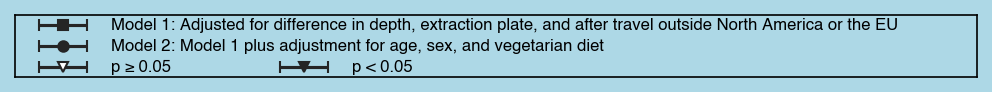

In [33]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 0.5), facecolor='lightblue')
def _plot_caption1(fig):
    """
    Helper function to make a legend
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.xaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.errorbar(x = [0.05], y=2, xerr=0.025, marker='s', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=1, xerr=0.025, marker='o', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markerfacecolor='w', markersize=5)
    ax.errorbar(x = [0.30], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markersize=5)
    
    ax.text(x=0.1, y=2, ha='left', va='center', size=8,
            s=('Model 1: Adjusted for difference in depth, extraction plate, and after travel outside North America or the EU'))
    ax.text(x=0.1, y=1, ha='left', va='center', size=8,
            s=('Model 2: Model 1 plus adjustment for age, sex, and vegetarian diet'))
    ax.text(x=0.1, y=0, ha='left', va='center', size=8, s=('p ≥ 0.05'))
    ax.text(x=0.35, y=0, ha='left', va='center', size=8, s=('p < 0.05'))
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlim(0, 1)
_plot_caption1(fig)

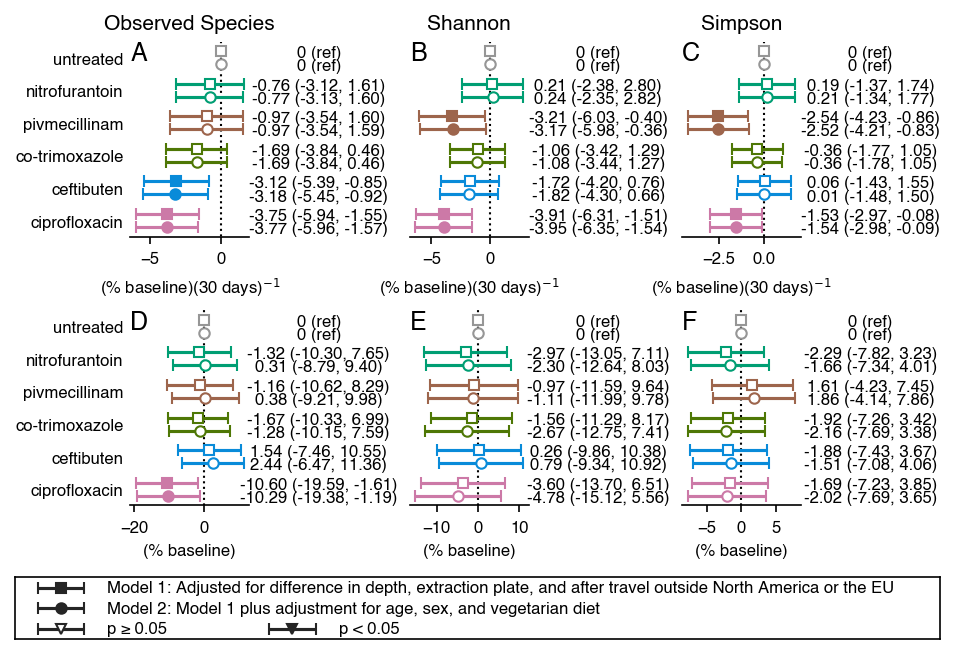

In [34]:
fig1 = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 4.25))
fig1a, fig1b = fig1.subfigures(2, 1, height_ratios=[3.75, 0.5], facecolor='None')


_wrap_forest(fig1a, sub_re.reset_index())
_plot_caption1(fig1b)

**Figure S7.  The effect of antibiotic treatment on microbial alpha diversity with an without baseline participant characteristics.**
Alpha diversity was model using a -perturbation-recovery model, which has two parameters: (A-C) the rate of recovery and (D-F) the new steady state. Data was modeled using a random effects framework; model 1 (square) was adjusted for extraction plate, difference between baseline and sample depth, and whether the sample was collected after travel. Model 2 (circle) was adjusted for model 1 as well as the participant age, sex, and whether they consumed a vegetarian diet. Filled circles indicate a statistically significant (p < 0.05) effect. Data was analyzed for (A,D) Observed Species, (B,E) Shannon diversity, and (C,F) Simpson diversity, which place increasing emphasis on evenness.

## Random intercept vs Random Slope

In [35]:
sub_re_rs = fit_unt_params.copy().xs('model 2', level='model')
sub_re_rs.reset_index(level=['ref_value'], drop=True, inplace=True)
sub_re_rs.reset_index(inplace=True)

sub_re_rs['width'] = sub_re_rs['ci_hi'] - sub_re['params']
sub_re_rs['tidy'] = sub_re_rs.apply(
    lambda x: '{params:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
sub_re_rs['tidy'] = \
    sub_re_rs['tidy'].mask(sub_re_rs['abx_code'].isin(['0', 0]), '0 (ref)')
sub_re_rs['params'] = sub_re_rs['params'].mask(sub_re_rs['abx_code'].isin(['0', 0]), 0)
sub_re_rs['width'] = sub_re_rs['width'].mask(sub_re_rs['abx_code'].isin(['0', 0]), np.nan)
sub_re_rs['p_value'] = sub_re_rs['p_value'].mask(sub_re_rs['abx_code'].isin(['0', 0]), 1)


sub_re_rs['y'] = 5 - sub_re_rs['abx_code'].astype(int) + \
    (sub_re_rs['rs_slope'] * -2 + 1) * 0.2
sub_re_rs['color'] = sub_re_rs['abx_code'].replace(abx_colors)
sub_re_rs['facecolor'] = sub_re_rs['color'].mask(sub_re_rs['p_value'] >= 0.05, 'w')
sub_re_rs['marker'] = sub_re_rs['rs_slope'].replace({0: 's', 1: 'D'})



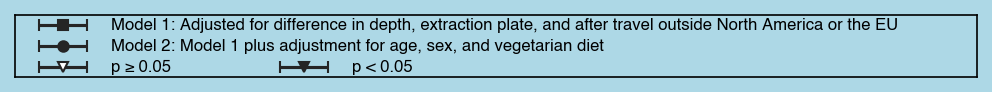

In [36]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 0.5), facecolor='lightblue')
def _plot_caption2(fig):
    """
    Helper function to make a legend
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.xaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.errorbar(x = [0.05], y=1, xerr=0.025, marker='s', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.30], y=1, xerr=0.025, marker='o', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markerfacecolor='w', markersize=5)
    ax.errorbar(x = [0.30], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markersize=5)
    
    ax.text(x=0.025, y=2, ha='left', va='center', size=8,
            s=('Adjusted for difference in depth, extraction plate, and after travel outside North America or the EU'))
    ax.text(x=0.1, y=1, ha='left', va='center', size=8, s=('Main model'))
    ax.text(x=0.35, y=1, ha='left', va='center', size=8, s=('With personal rate of recovery'))
    ax.text(x=0.1, y=0, ha='left', va='center', size=8, s=('p ≥ 0.05'))
    ax.text(x=0.35, y=0, ha='left', va='center', size=8, s=('p < 0.05'))
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlim(0, 1)
_plot_caption1(fig)

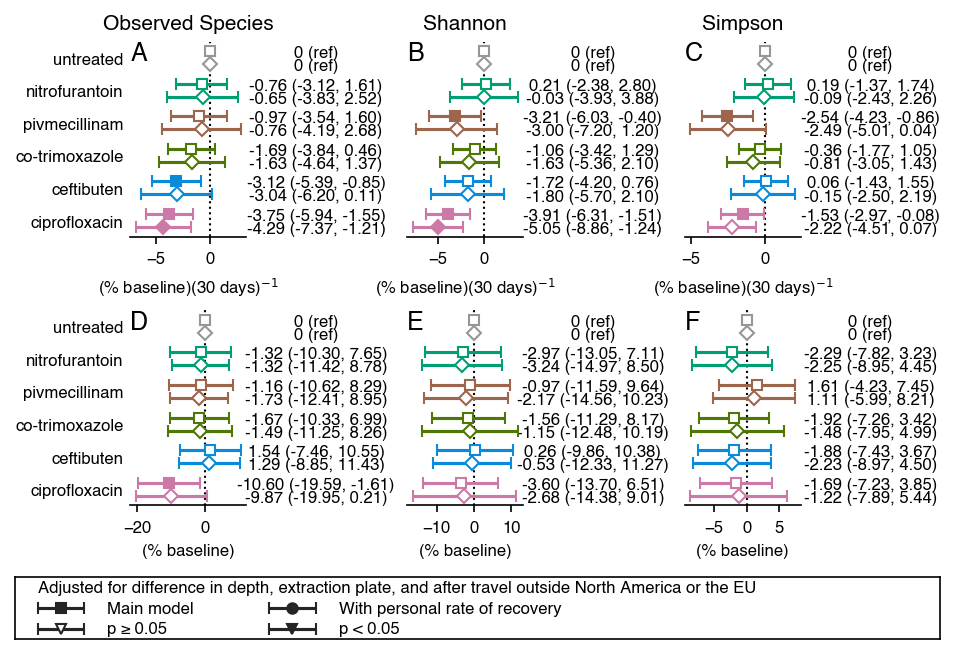

In [37]:
fig1 = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 4.25))
fig1a, fig1b = fig1.subfigures(2, 1, height_ratios=[3.75, 0.5], facecolor='None')


_wrap_forest(fig1a, sub_re_rs)
_plot_caption2(fig1b)

**Figure S8. Individual effects on the change in alpha diversity in response to antibiotic treatment.** The effect of antibiotic treatment on the microbiome using a treatment/recovery model, which had two parameters: (A-C) the rate of recovery and (D-F) the new steady state. The data was modeled using a linear mixed effect model with a random intercept (square), allowing participants to recover to a new steady state or random intercept and random slope (diamond), allowing both a new steady state and an individual rate of recovery. Both models were adjusted for extraction plate, difference between baseline and sample depth, and whether the sample was collected after travel. Filled symbols indicate a statistically significant (p < 0.05) effect. Data was analyzed for (A,D) Observed Species, (B,E) Shannon diversity, and (C,F) Simpson diversity, which place increasing emphasis on evenness, indicating a larger change in abundance.